# 7 — Mise en classe du score (CHR) · Segment : Comptes joints

Chapitre 7 du cours : transformer le score en points (grille PDO du notebook `6`) en un nombre restreint de
**Classes Homogènes de Risque (CHR)**, dernière étape de la *risk differentiation* avant le calibrage (ch. 8).

| Étape | Question | Section |
|-------|----------|---------|
| 7.1 | Comment construire le découpage : découpage fin puis fusion de classes adjacentes ? | Construction |
| 7.2 | Les CHR sont-elles stables en risque et en volume dans le temps ? | Stabilité |
| 7.3 | Une variable exogène révèle-t-elle des sous-populations de risque différent dans une CHR ? | Homogénéité |
| 7.4 | Deux CHR adjacentes sont-elles assez différentes (écart relatif ≥ 30 %) ? | Hétérogénéité |
| 7.5 | Faut-il une échelle maître ? | Échelle maître |
| 7.6 | Quelle part du pouvoir discriminant la mise en classe fait-elle perdre ? | Perte d'information |

> Convention : **CHR 1 = la moins risquée**, CHR K = la plus risquée. Les bornes sont apprises sur l'**apprentissage**
> seul, puis appliquées au test (et plus tard à l'OOT) sans être modifiées.

## 0. Imports et configuration

In [1]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from utils.modele import appliquer_fusions
from utils.scorecard import noter
from utils.binning import stabilite_decoupages, plot_stabilite
from utils.chr import (
    construire_chr, affecter_chr, libelles_chr, table_chr, homogeneite_exogene, binariser_mediane,
    perte_information, plot_chr, plot_bornes_score, chr_optbinning, comparer_decoupages,
)
from utils.exploration import exporter_excel

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(16)

polars.config.Config

### Paramètres

In [2]:
VERSION = "_v2"     # "" : modèle de référence (5 / 6) ; "_v2" : variante (5_v2 / 6_v2)

BASE_CL  = ROOT.parent / "data/segments/joint/base_joint_classes.parquet"   # variables en classes (sortie de 4)
BASE_ORI = ROOT.parent / "data/segments/joint/base_joint.parquet"           # base du segment, pour les variables exogènes
GRILLE   = ROOT / f"outputs/scorecard/grille_joint{VERSION}.json"
SORTIE   = ROOT / f"outputs/chr/chr_joint{VERSION}.json"
SORTIE_XLS = ROOT / f"outputs/chr/chr_joint{VERSION}.xlsx"

TARGET   = "ddefaut_ndb"
ID_COL   = "gdt"
DATE_COL = "datdelhis"
COHORTE  = "1mo"            # cohortes mensuelles, comme au ch. 4

# Règles de construction des CHR (cours 7.1 à 7.4)
N_FIN       = 20            # découpage fin : 20 quantiles du score
SEUIL       = 0.30          # écart relatif minimal de taux de défaut entre CHR adjacentes
MIN_DEFAUTS = 5             # défauts minimum par CHR (en apprentissage)
MIN_PART    = 0.02          # effectif minimum par CHR (2 % de l'apprentissage)
ALPHA       = 0.05
SEUIL_PSI   = 0.10
MAX_PART    = 0.40          # effectif maximum par CHR (50 % de l'apprentissage)

# Variables exogènes au score (cours 7.3.1) : non testées dans le modèle
EXOGENES = ["age", "age_ans", "nb_tiers", "code_marche_v2", "type_PM_PP"]

## 1. Chargement : score en points de chaque dossier

In [3]:
g = json.loads(GRILLE.read_text(encoding="utf-8"))
VARS = g["variables"]
FUSIONS = {v: {int(a): b for a, b in f.items()} for v, f in g["fusions"].items()}
grille = pl.DataFrame(g["grille_pdo"])

df = appliquer_fusions(pl.read_parquet(BASE_CL), FUSIONS)
df = noter(df, grille, "points").with_columns(cohorte=pl.col(DATE_COL).dt.truncate(COHORTE).dt.to_string("%Y-%m"))
df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")

print(f"Grille PDO de {len(VARS)} variables ({GRILLE.name}) | "
      f"apprentissage : {df_app.height} dossiers, {int(df_app[TARGET].sum())} défauts | "
      f"test : {df_test.height} dossiers, {int(df_test[TARGET].sum())} défauts")
print(f"{df_app['points'].n_unique()} valeurs de score distinctes en apprentissage "
      f"(de {df_app['points'].min():.0f} à {df_app['points'].max():.0f} points)")

Grille PDO de 9 variables (grille_joint_v2.json) | apprentissage : 47156 dossiers, 228 défauts | test : 11791 dossiers, 56 défauts
208 valeurs de score distinctes en apprentissage (de 483 à 738 points)


## 7.1 Construction des CHR

### 7.1.2 Le score d'une grille n'est pas continu

Le score est la somme des points des modalités : il ne prend qu'un nombre fini de valeurs (au plus le produit des
nombres de classes des variables), d'où des **paliers**. Une borne placée au milieu d'un palier séparerait deux
dossiers de score identique : les bornes sont donc toujours prises **entre deux valeurs observées** du score.

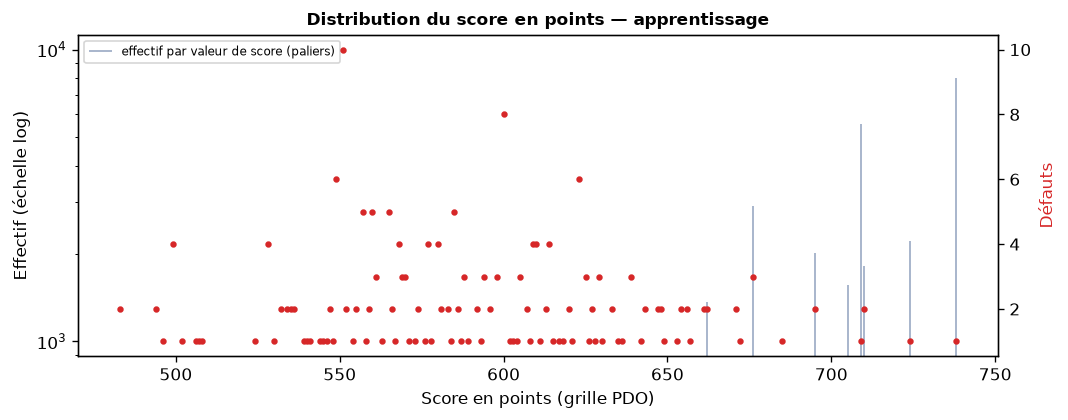

In [4]:
fig = plot_bornes_score(df_app["points"], df_app[TARGET], [], titre="Distribution du score en points — apprentissage")
plt.show()

**Lecture** : 208 valeurs de score distinctes en apprentissage, de 483 à 738 points. La masse des dossiers est
concentrée sur quelques paliers élevés (profils proches de « toutes classes de référence ») : un découpage fin en 20
quantiles ne produit donc qu'une quinzaine de classes distinctes, puisqu'un palier n'est jamais coupé.

### 7.1.3 Découpage fin puis fusion

Découpage fin en 20 quantiles du score (bornes sur les valeurs observées), puis fusions successives de **deux classes
adjacentes**, une à la fois, par ordre de priorité :

1. classe trop petite (< 2 % des dossiers ou < 5 défauts) → elle rejoint sa voisine de taux le plus proche ;
2. rupture de monotonie (une classe moins bien notée n'est pas plus risquée) ;
3. écart relatif de taux de défaut avec la voisine **< 30 %** (7.2.1 / 7.4).

Deux variantes de la règle 3 sont comparées :

- **ponctuelle** : $R_k = \tau_k / \tau_{k-1} - 1 \geq 30\,\%$ ;
- **avec IC** (cours 7.2.1, « pour aller plus loin ») : la borne basse de l'IC à 95 % de $R_k$, par la méthode delta,
  doit rester ≥ 30 %. Plus exigeante, elle tient compte du faible nombre de défauts.

In [5]:
resultats = {}
for nom, critere, max_part in (("ponctuel", "ponctuel", MAX_PART), ("ic", "ic", MAX_PART), ("ic_sans_max", "ic", None)):
    bornes, journal = construire_chr(df_app["points"], df_app[TARGET], n_fin=N_FIN, seuil=SEUIL, critere=critere,
                                     min_defauts=MIN_DEFAUTS, min_part=MIN_PART, max_part=max_part, alpha=ALPHA)
    d = df_app.with_columns(CHR=pl.Series(affecter_chr(df_app["points"], bornes)))
    resultats[nom] = (bornes, journal, table_chr(d, "CHR", TARGET, SEUIL, ALPHA, points="points"))
    print(f"{nom:12s} : {len(bornes) + 1} CHR | bornes = {bornes} | {journal.height} fusions")

ponctuel     : 8 CHR | bornes = [598.0, 620.0, 633.0, 647.0, 662.0, 676.0, 709.0] | 7 fusions
ic           : 5 CHR | bornes = [598.0, 633.0, 676.0, 709.0] | 10 fusions
ic_sans_max  : 4 CHR | bornes = [598.0, 633.0, 656.0] | 11 fusions


In [6]:
for critere, (bornes, journal, t) in resultats.items():
    print(f"=== critère {critere}")
    display(t.with_columns(libelle=pl.col("CHR").replace_strict(libelles_chr(bornes)))
             .select("CHR", "libelle", "n", "part", "n_defaut", "taux_defaut", "R", "R_ic_bas", "R_ic_haut",
                     "ecart_ok", "ecart_ic_ok"))

=== critère ponctuel


CHR,libelle,n,part,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
i64,str,u32,f64,f64,f64,f64,f64,f64,bool,bool
1,"""> 709""",12573,0.266626,4.0,0.000318,null,null,null,null,null
2,"""]676 ; 709]""",15223,0.322822,4.0,0.000263,-0.174079,-1.31856,0.970403,false,false
3,"""]662 ; 676]""",5204,0.110357,6.0,0.001153,3.387875,-2.161733,8.937482,true,false
4,"""]647 ; 662]""",4610,0.097761,13.0,0.00282,1.445842,-0.918123,3.809808,true,false
5,"""]633 ; 647]""",2459,0.052146,10.0,0.004067,0.442112,-0.744674,1.628899,true,false
6,"""]620 ; 633]""",2353,0.049898,20.0,0.0085,1.090098,-0.492072,2.672267,true,false
7,"""]598 ; 620]""",2305,0.04888,37.0,0.016052,0.888525,-0.13302,1.91007,true,false
8,"""≤ 598""",2429,0.05151,134.0,0.055167,2.436739,1.201219,3.672258,true,true


=== critère ic


CHR,libelle,n,part,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
i64,str,u32,f64,f64,f64,f64,f64,f64,bool,bool
1,"""> 709""",12573,0.266626,4.0,0.000318,null,null,null,null,null
2,"""]676 ; 709]""",15223,0.322822,4.0,0.000263,-0.174079,-1.31856,0.970403,false,false
3,"""]633 ; 676]""",12273,0.260264,29.0,0.002363,7.992646,-1.405695,17.390988,true,false
4,"""]598 ; 633]""",4658,0.098779,57.0,0.012237,4.178788,1.870184,6.487391,true,true
5,"""≤ 598""",2429,0.05151,134.0,0.055167,3.508187,2.128539,4.887835,true,true


=== critère ic_sans_max


CHR,libelle,n,part,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
i64,str,u32,f64,f64,f64,f64,f64,f64,bool,bool
1,"""> 656""",34950,0.741157,19.0,0.000544,null,null,null,null,null
2,"""]633 ; 656]""",5119,0.108555,18.0,0.003516,5.468163,1.302666,9.63366,true,true
3,"""]598 ; 633]""",4658,0.098779,57.0,0.012237,2.48007,0.641113,4.319027,true,true
4,"""≤ 598""",2429,0.05151,134.0,0.055167,3.508187,2.128539,4.887835,true,true


### Comparaison avec des CHR construites par optbinning

La librairie **optbinning** (`OptimalBinning`) découpe le score par un pré-découpage en arbre (20 classes) puis une
optimisation sous contraintes qui maximise l'IV. On lui impose les mêmes contraintes que ci-dessus : taux de défaut
décroissant avec les points, au moins 2 % des dossiers et 5 défauts par classe. Elle n'a pas de règle d'écart relatif
de 30 % : celle-ci est contrôlée après coup. Trois variantes :

- **optbinning libre** : nombre de classes choisi par l'optimisation ;
- **optbinning, 20 défauts min.** : contrainte d'effectif plus forte ;
- **optbinning, 4 classes max.** : nombre de CHR imposé.

Toutes sont évaluées avec les critères du chapitre (7.2, 7.4, 7.6) et comparées aux découpages par fusions ci-dessus.

In [7]:
DECOUPAGES = {
    "fusions, IC de R ≥ 30 %, part max. 40 %": resultats["ic"][0],
    "fusions, IC de R ≥ 30 %, sans part max.": resultats["ic_sans_max"][0],
    "fusions, 30 % ponctuel": resultats["ponctuel"][0],
    "optbinning libre": chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=MIN_PART, min_bin_n_event=MIN_DEFAUTS),
    "optbinning, 20 défauts min.": chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=MIN_PART, min_bin_n_event=20),
    "optbinning, 4 classes max.": chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=MIN_PART,
                                                 min_bin_n_event=MIN_DEFAUTS, max_n_bins=4),
}
comparaison = comparer_decoupages(df_app, df_test, DECOUPAGES, TARGET, seuil=SEUIL, alpha=ALPHA)
with pl.Config(tbl_cols=-1, fmt_str_lengths=90, tbl_width_chars=250):
    display(comparaison)

decoupage,n_chr,bornes,parts_app,defauts_app,taux_app,ecart_30_app,ic_30_app,ordre_test,cohortes_ordonnees,gini_chr_app,gini_chr_test,delta_gini_test
str,i64,str,str,str,str,bool,bool,bool,f64,f64,f64,f64
"""fusions, IC de R ≥ 30 %, part max. 40 %""",5,"""598 · 633 · 676 · 709""","""26.7% · 32.3% · 26.0% · 9.9% · 5.2%""","""4 · 4 · 29 · 57 · 134""","""0.03% · 0.03% · 0.24% · 1.22% · 5.52%""",false,false,false,0.25,0.801338,0.772156,0.024043
"""fusions, IC de R ≥ 30 %, sans part max.""",4,"""598 · 633 · 656""","""74.1% · 10.9% · 9.9% · 5.2%""","""19 · 18 · 57 · 134""","""0.05% · 0.35% · 1.22% · 5.52%""",true,true,true,1.0,0.785873,0.744642,0.051557
"""fusions, 30 % ponctuel""",8,"""598 · 620 · 633 · 647 · 662 · 676 · 709""","""26.7% · 32.3% · 11.0% · 9.8% · 5.2% · 5.0% · 4.9% · 5.2%""","""4 · 4 · 6 · 13 · 10 · 20 · 37 · 134""","""0.03% · 0.03% · 0.12% · 0.28% · 0.41% · 0.85% · 1.61% · 5.52%""",false,false,false,0.0,0.813709,0.776593,0.019606
"""optbinning libre""",6,"""600 · 629 · 649 · 661 · 695""","""46.3% · 26.6% · 5.9% · 8.0% · 7.5% · 5.7%""","""5 · 11 · 8 · 16 · 46 · 142""","""0.02% · 0.09% · 0.29% · 0.43% · 1.30% · 5.25%""",true,false,false,0.5,0.816108,0.774346,0.021853
"""optbinning, 20 défauts min.""",3,"""600 · 649""","""78.8% · 15.5% · 5.7%""","""24 · 62 · 142""","""0.06% · 0.85% · 5.25%""",true,true,true,1.0,0.767163,0.747028,0.049171
"""optbinning, 4 classes max.""",4,"""600 · 629 · 676""","""58.9% · 27.8% · 7.5% · 5.7%""","""8 · 32 · 46 · 142""","""0.03% · 0.24% · 1.30% · 5.25%""",true,true,true,1.0,0.804182,0.766361,0.029837


In [8]:
for nom in [n for n in DECOUPAGES if n.startswith("optbinning")]:
    b = DECOUPAGES[nom]
    t = table_chr(df_test.with_columns(CHR=pl.Series(affecter_chr(df_test["points"], b))), "CHR", TARGET, SEUIL, ALPHA)
    a = table_chr(df_app.with_columns(CHR=pl.Series(affecter_chr(df_app["points"], b))), "CHR", TARGET, SEUIL, ALPHA)
    print(f"=== {nom} : {len(b) + 1} CHR, bornes {b}")
    display(a.select("CHR", "n", "part", "n_defaut", "taux_defaut", "R", "R_ic_bas", "ecart_ok", "ecart_ic_ok")
             .join(t.select("CHR", n_defaut_test="n_defaut", taux_test="taux_defaut"), on="CHR", how="left"))

=== optbinning libre : 6 CHR, bornes [600.0, 629.0, 649.0, 661.0, 695.0]


CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,n_defaut_test,taux_test
i64,u32,f64,f64,f64,f64,f64,bool,bool,f64,f64
1,21838,0.463101,5.0,0.000229,null,null,null,null,2.0,0.000367
2,12522,0.265544,11.0,0.000878,2.836735,-1.218301,true,false,5.0,0.001609
3,2795,0.059271,8.0,0.002862,2.258286,-0.706082,true,false,0.0,0.0
4,3753,0.079587,16.0,0.004263,0.489475,-0.77252,true,false,6.0,0.006479
5,3545,0.075176,46.0,0.012976,2.043688,0.317904,true,true,8.0,0.00883
6,2703,0.05732,142.0,0.052534,3.048561,1.717713,true,true,35.0,0.050651


=== optbinning, 20 défauts min. : 3 CHR, bornes [600.0, 649.0]


CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,n_defaut_test,taux_test
i64,u32,f64,f64,f64,f64,f64,bool,bool,f64,f64
1,37155,0.787917,24.0,0.000646,null,null,null,null,7.0,0.000755
2,7298,0.154763,62.0,0.008495,12.152062,5.96374,true,true,14.0,0.007642
3,2703,0.05732,142.0,0.052534,5.183786,3.359161,true,true,35.0,0.050651


=== optbinning, 4 classes max. : 4 CHR, bornes [600.0, 629.0, 676.0]


CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,n_defaut_test,taux_test
i64,u32,f64,f64,f64,f64,f64,bool,bool,f64,f64
1,27796,0.589448,8.0,0.000288,null,null,null,null,3.0,0.000431
2,13112,0.278056,32.0,0.002441,7.479561,0.912434,true,true,10.0,0.003089
3,3545,0.075176,46.0,0.012976,4.316925,1.926206,true,true,8.0,0.00883
4,2703,0.05732,142.0,0.052534,3.048561,1.717713,true,true,35.0,0.050651


**Lecture** :

| Découpage | CHR | Défauts par CHR (appr.) | IC de R ≥ 30 % | Ordre test | Cohortes ordonnées | Gini CHR test | Perte vs score |
|-----------|-----|-------------------------|----------------|------------|--------------------|---------------|----------------|
| fusions, IC, part max. 40 % | 5 | 4 · 4 · 29 · 57 · 134 | non | non | 25 % | 77,2 % | −2,4 pts |
| fusions, IC, sans part max. | 4 | 19 · 18 · 57 · 134 | oui | oui | 100 % | 74,5 % | −5,2 pts |
| fusions, 30 % ponctuel | 8 | 4 · 4 · 6 · 13 · 10 · 20 · 37 · 134 | non | non | 0 % | 77,7 % | −2,0 pts |
| optbinning libre | 6 | 5 · 11 · 8 · 16 · 46 · 142 | non | non | 50 % | 77,4 % | −2,2 pts |
| optbinning, 20 défauts min. | 3 | 24 · 62 · 142 | oui | oui | 100 % | 74,7 % | −4,9 pts |
| **optbinning, 4 classes max.** | **4** | **8 · 32 · 46 · 142** | **oui** | **oui** | **100 %** | **76,6 %** | **−3,0 pts** |

- **Fusions avec une part maximale de 40 %** : la contrainte empêche de regrouper les deux classes les mieux notées
  (26,7 % et 32,3 % des dossiers, 4 défauts chacune). Il reste donc 5 CHR dont les deux premières sont **inversées**
  (0,032 % puis 0,026 %) : cette variante viole la monotonie et est écartée.
- **Fusions sans part maximale** : les critères sont respectés, mais la CHR 1 regroupe 74 % des dossiers. Le Gini des
  CHR perd 5 points.
- Les découpages à 6 ou 8 classes gardent plus de Gini, mais leurs CHR de 4 à 16 défauts se croisent sur le test et
  d'un mois à l'autre.
- **optbinning à 4 classes** passe **tous** les critères du chapitre et perd le moins de Gini parmi les découpages
  stables (76,6 % en test). L'optimisation globale de l'IV place mieux les bornes que nos fusions pas à pas, qui ne
  choisissent que la meilleure fusion locale à chaque étape. Contrepartie : sa CHR 1 n'a que 8 défauts, d'où une
  PD moins précise au calibrage (MoC A plus forte, ch. 8).

### Choix du découpage

**Décision : optbinning à 4 classes** (bornes 600 · 629 · 676 points). C'est le meilleur Gini parmi les découpages qui
respectent tous les critères du chapitre : écart relatif et borne basse de son IC ≥ 30 % en apprentissage, ordre
respecté sur le test et dans toutes les cohortes. Les découpages par fusions (section 7.1.3) sont conservés pour
documentation. Leur journal est exporté.

In [9]:
CHOIX = "optbinning, 4 classes max."     # décision validée (voir « Choix du découpage »)
BORNES = DECOUPAGES[CHOIX]
JOURNAL = resultats["ic"][1]              # journal des fusions de la variante par fusions (documentation)
LIBELLES = libelles_chr(BORNES)
K = len(BORNES) + 1

df = df.with_columns(CHR=pl.Series(affecter_chr(df["points"], BORNES)))
df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")

tab_app  = table_chr(df_app, "CHR", TARGET, SEUIL, ALPHA, points="points")
tab_test = table_chr(df_test, "CHR", TARGET, SEUIL, ALPHA, points="points")
print(f"Découpage retenu : {CHOIX} → {K} CHR, bornes {BORNES}")

Découpage retenu : optbinning, 4 classes max. → 4 CHR, bornes [600.0, 629.0, 676.0]


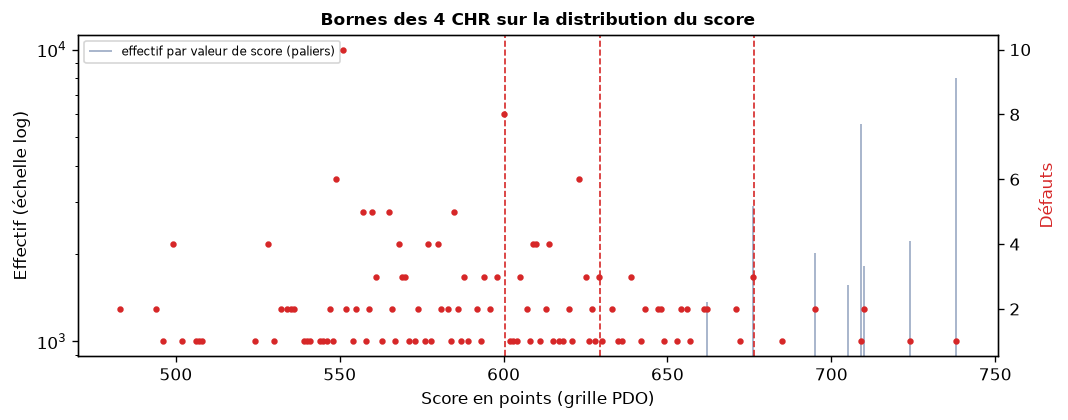

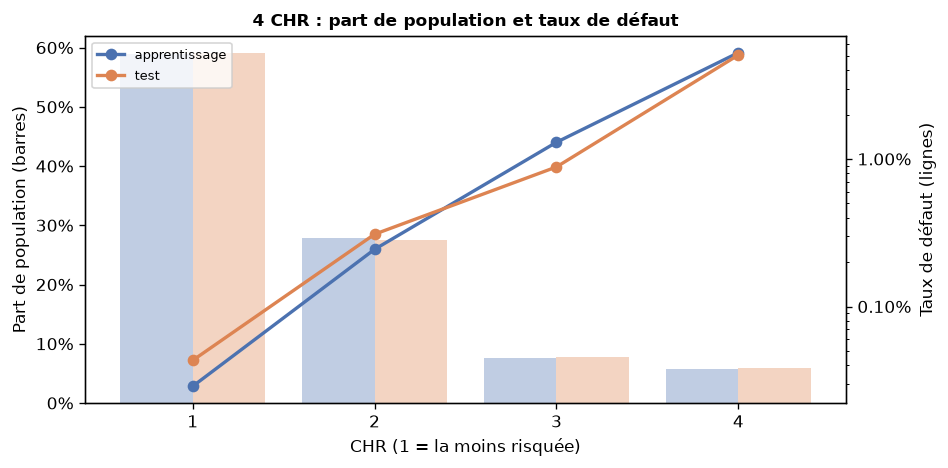

In [10]:
fig = plot_bornes_score(df_app["points"], df_app[TARGET], BORNES, titre=f"Bornes des {K} CHR sur la distribution du score")
plt.show()
fig = plot_chr({"apprentissage": tab_app, "test": tab_test}, titre=f"{K} CHR : part de population et taux de défaut")
plt.show()

In [11]:
pl.concat([
    tab_app.select(pl.lit("apprentissage").alias("echantillon"), "CHR", "n", "part", "n_defaut", "taux_defaut", "R"),
    tab_test.select(pl.lit("test").alias("echantillon"), "CHR", "n", "part", "n_defaut", "taux_defaut", "R"),
]).with_columns(libelle=pl.col("CHR").replace_strict(LIBELLES)).sort("CHR", "echantillon")

echantillon,CHR,n,part,n_defaut,taux_defaut,R,libelle
str,i64,u32,f64,f64,f64,f64,str
"""apprentissage""",1,27796,0.589448,8.0,0.000288,null,"""> 676"""
"""test""",1,6957,0.590026,3.0,0.000431,null,"""> 676"""
"""apprentissage""",2,13112,0.278056,32.0,0.002441,7.479561,"""]629 ; 676]"""
"""test""",2,3237,0.274531,10.0,0.003089,6.164041,"""]629 ; 676]"""
"""apprentissage""",3,3545,0.075176,46.0,0.012976,4.316925,"""]600 ; 629]"""
"""test""",3,906,0.076838,8.0,0.00883,1.858278,"""]600 ; 629]"""
"""apprentissage""",4,2703,0.05732,142.0,0.052534,3.048561,"""≤ 600"""
"""test""",4,691,0.058604,35.0,0.050651,4.736252,"""≤ 600"""


**Lecture** : 4 CHR aux taux de défaut très séparés (environ ×8, ×5 et ×4 d'une CHR à la suivante) :

| CHR | Score | Part (appr. / test) | Défauts (appr. / test) | Taux de défaut (appr. / test) |
|-----|-------|---------------------|------------------------|-------------------------------|
| 1 | > 676 | 58,9 % / 59,0 % | 8 / 3 | 0,03 % / 0,04 % |
| 2 | 630 – 676 | 27,8 % / 27,5 % | 32 / 10 | 0,24 % / 0,31 % |
| 3 | 601 – 629 | 7,5 % / 7,7 % | 46 / 8 | 1,30 % / 0,88 % |
| 4 | ≤ 600 | 5,7 % / 5,9 % | 142 / 35 | 5,25 % / 5,07 % |

Les parts se reproduisent sur le test à moins d'un demi-point. Les taux aussi, aux fluctuations près des petites
classes (CHR 3 : 8 défauts en test). La CHR 1 regroupe 59 % du portefeuille : c'est le reflet d'un portefeuille très
peu risqué (0,48 % de défaut).

## 7.2 Stabilité en risque et en volume dans le temps

Pour chaque cohorte mensuelle de l'apprentissage, puis entre apprentissage et test :

- **risque** : l'ordre $TD_{1,t} \leq \dots \leq TD_{K,t}$ doit tenir dans chaque cohorte, et l'écart relatif moyen
  entre CHR adjacentes doit rester ≥ 30 % ;
- **volume** : la part de chaque CHR doit rester stable (PSI ≤ 0,10, formalisé en 9.3).

Attention à ne pas confondre stabilité et stationnarité : un taux de défaut qui monte dans toutes les CHR à la fois
n'est pas une instabilité.

In [12]:
detail_coh, stab_coh = stabilite_decoupages(df_app, ["CHR"], TARGET, "cohorte", seuil_ecart=SEUIL, seuil_psi=SEUIL_PSI)
detail_ech, stab_ech = stabilite_decoupages(df, ["CHR"], TARGET, "echantillon", seuil_ecart=SEUIL, seuil_psi=SEUIL_PSI)
display(pl.concat([stab_coh.with_columns(groupe=pl.lit("cohortes de l'apprentissage")),
                   stab_ech.with_columns(groupe=pl.lit("apprentissage / test"))]).drop("variable"))
detail_coh.select("groupe", "classe", "n", "n_defaut", "part", "taux_defaut", "ecart_relatif").pivot(
    on="groupe", index="classe", values=["part", "taux_defaut"]).sort("classe")

ecart_moyen_min,part_groupes_ordonnes,psi_max,stable_risque,stable_volume,groupe
f64,f64,f64,bool,bool,str
3.088413,1.0,0.000133,true,true,"""cohortes de l'apprentissage"""
3.087602,1.0,0.000071,true,true,"""apprentissage / test"""


classe,part_2021-01,part_2021-02,part_2021-03,part_2021-04,taux_defaut_2021-01,taux_defaut_2021-02,taux_defaut_2021-03,taux_defaut_2021-04
i64,f64,f64,f64,f64,f64,f64,f64,f64
1,0.588406,0.585163,0.592025,0.592182,0.00029,0.00029,0.0,0.000572
2,0.280818,0.280967,0.276752,0.273712,0.003947,0.003018,0.000612,0.002164
3,0.075192,0.075625,0.074839,0.075049,0.011338,0.011211,0.015837,0.013529
4,0.055584,0.058245,0.056383,0.059057,0.052147,0.042213,0.051051,0.06447


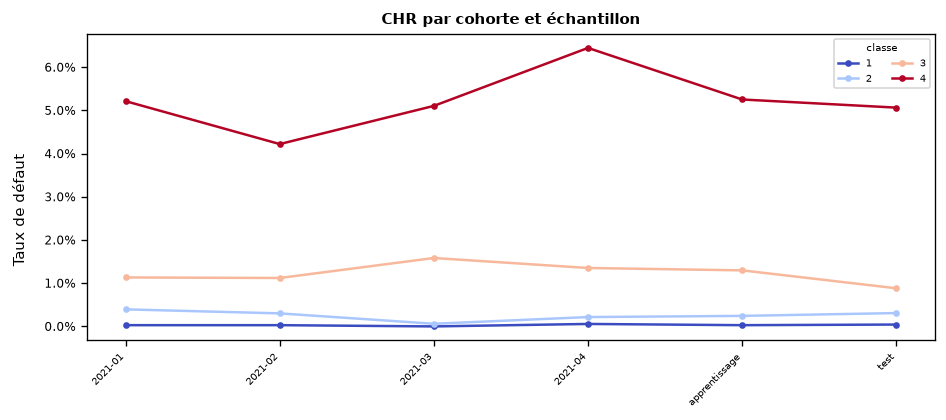

In [13]:
fig = plot_stabilite(pl.concat([detail_coh, detail_ech]).with_columns(variable=pl.lit("CHR par cohorte et échantillon")),
                     ["CHR par cohorte et échantillon"], n_cols=1, figsize_par_plot=(8, 3.6))
plt.show()

**Lecture** :

- **Risque** : l'ordre des 4 CHR est respecté dans **100 % des cohortes** mensuelles et entre apprentissage et test. L'écart
  relatif moyen le plus faible entre deux CHR adjacentes est de 309 % (seuil 30 %). Le taux mensuel de la CHR 2 varie de
  0,06 % à 0,39 % (2 à 13 défauts par mois), mais reste toujours entre ceux des CHR 1 et 3.
- **Volume** : les parts des CHR varient de moins d'un point d'un mois à l'autre (CHR 1 : 58,5 % à 59,2 %). PSI max =
  0,0001, pour un seuil de 0,10.
- Réserve : la base ne couvre que 4 mois d'une même année ; la stabilité sur un cycle sera vérifiée sur l'OOT.

## 7.3 Homogénéité intra-CHR selon une variable exogène

Question : **dans une même CHR**, une information extérieure au score distingue-t-elle encore des dossiers de risque
différent ? On utilise des variables **non testées dans le modèle** (cours 7.3.1) : les variables rejetées au
stepwise ne sont pas pertinentes ici. Retenues, si présentes dans la base :

- l'**âge** : volontairement exclu du modèle pour raison réglementaire (2, § 2.5) — exemple cité par le cours ;
- le **nombre de titulaires** du compte joint, le **code marché** : variables de segmentation, hors du score.

Pour chaque CHR et chaque modalité (comparée au reste de la CHR) : **test de Welch** et **h de Cohen**. Une CHR n'est
jugée hétérogène que si l'écart est **à la fois** significatif (p < 5 %) et non négligeable (|h| ≥ 0,2), le test de
Welch étant très puissant sur de grands effectifs (7.3.2).

In [14]:
cles = [ID_COL, DATE_COL]
exo_dispo = [c for c in EXOGENES if c in pl.read_parquet_schema(BASE_ORI)]
print(f"Variables exogènes disponibles : {exo_dispo}")

exo = pl.read_parquet(BASE_ORI, columns=cles + exo_dispo)
assert exo.select(cles).is_duplicated().sum() == 0, "clé (gdt, date) non unique"
d_exo = df.select(cles + ["echantillon", "CHR", TARGET]).join(exo, on=cles, how="left")

app_exo = d_exo.filter(pl.col("echantillon") == "apprentissage")
# Variable quasi constante sur le segment (modalité majoritaire ≥ 99 %) : rien à tester
part_max = {v: app_exo[v].cast(pl.String).value_counts(normalize=True)["proportion"].max() for v in exo_dispo}
exo_dispo = [v for v in exo_dispo if part_max[v] < 0.99]
print(f"Variables testées (non quasi constantes) : {exo_dispo}")
# Variable numérique à plus de 2 valeurs : deux groupes autour de la médiane de l'apprentissage
for v in exo_dispo:
    if d_exo[v].dtype.is_numeric() and d_exo[v].n_unique() > 2:
        med = float(app_exo[v].median())
        d_exo = d_exo.with_columns(binariser_mediane(d_exo, v, med))

homog = pl.concat([homogeneite_exogene(d_exo.filter(pl.col("echantillon") == "apprentissage"), "CHR", TARGET, v,
                                       alpha=ALPHA) for v in exo_dispo])
with pl.Config(tbl_rows=-1, fmt_str_lengths=40):
    display(homog)

Variables exogènes disponibles : ['age', 'age_ans', 'nb_tiers', 'code_marche_v2', 'type_PM_PP']
Variables testées (non quasi constantes) : ['age', 'age_ans', 'nb_tiers']


variable,CHR,modalite,n_a,n_b,taux_a,taux_b,t,pvalue,h,taille_effet,conclusion
str,i64,str,i64,i64,f64,f64,f64,f64,f64,str,str
"""age""",1,"""18-25""",46,27750,0.0,0.000288,null,null,null,null,"""effectif insuffisant"""
"""age""",1,"""25-40""",3320,24476,0.000301,0.000286,0.047537,0.962087,0.000888,"""négligeable""","""homogène"""
"""age""",1,"""40-60""",10029,17767,0.0001,0.000394,-1.642299,0.100539,-0.01973,"""négligeable""","""homogène"""
"""age""",1,"""60+""",14401,13395,0.000417,0.000149,1.335572,0.181702,0.016387,"""négligeable""","""homogène"""
"""age""",2,"""18-25""",96,13016,0.0,0.002459,null,null,null,null,"""effectif insuffisant"""
"""age""",2,"""25-40""",2766,10346,0.002169,0.002513,-0.339661,0.734127,-0.00712,"""négligeable""","""homogène"""
"""age""",2,"""40-60""",5628,7484,0.002843,0.002138,0.793851,0.427299,0.014181,"""négligeable""","""homogène"""
"""age""",2,"""60+""",4622,8490,0.002164,0.002591,-0.486952,0.626303,-0.008791,"""négligeable""","""homogène"""
"""age""",3,"""18-25""",38,3507,0.0,0.013117,null,null,null,null,"""effectif insuffisant"""


In [15]:
homog.group_by("variable", "conclusion").len().sort("variable", "conclusion")

variable,conclusion,len
str,str,u32
"""age""","""effectif insuffisant""",4
"""age""","""homogène""",10
"""age""","""écart significatif mais néglig…",2
"""age_ans""","""homogène""",3
"""age_ans""","""écart significatif mais néglig…",1
"""nb_tiers""","""effectif insuffisant""",2
"""nb_tiers""","""homogène""",1
"""nb_tiers""","""écart significatif mais néglig…",1


**Lecture** : **aucune CHR n'est hétérogène**.

- `code_marche_v2` et `type_PM_PP` sont quasi constants sur le segment : rien à tester.
- **Âge** (tranches, et âge en deux groupes autour de la médiane de 56 ans) : homogène dans les CHR 1 à 3. En CHR 4, les
  écarts sont significatifs mais **négligeables** (|h| ≤ 0,12) : les 40 – 60 ans y font un peu plus défaut, les plus de
  60 ans un peu moins. Ce résultat conforte l'exclusion de l'âge du modèle (2, § 2.5) : il n'apporte pas d'information
  de risque que les CHR ne captent déjà.
- **Nombre de titulaires** (2 contre 3 et plus) : seule la CHR 1 compte assez de comptes à 3 titulaires. L'écart y est
  significatif mais négligeable (h = −0,03, aucun défaut sur 201 dossiers).
- Les sous-groupes de moins de 100 dossiers ne sont pas testés : 18 – 25 ans, comptes à 3 titulaires des CHR 3 et 4.

## 7.4 Hétérogénéité inter-CHR

Deux CHR adjacentes doivent avoir des niveaux de risque suffisamment différents : $R_k \geq 30\,\%$ et, pour aller plus
loin, la borne basse de l'IC de $R_k$ ≥ 30 %. Le cours rappelle que c'est une **décision métier** : deux CHR à 25 %
d'écart qui ne se croisent jamais peuvent être conservées. Contrôle sur l'apprentissage et sur le test.

In [16]:
pl.concat([
    tab_app.select(pl.lit("apprentissage").alias("echantillon"), "CHR", "n_defaut", "taux_defaut", "R", "R_ic_bas",
                   "R_ic_haut", "ecart_ok", "ecart_ic_ok"),
    tab_test.select(pl.lit("test").alias("echantillon"), "CHR", "n_defaut", "taux_defaut", "R", "R_ic_bas",
                    "R_ic_haut", "ecart_ok", "ecart_ic_ok"),
]).filter(pl.col("R").is_not_null())

echantillon,CHR,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
str,i64,f64,f64,f64,f64,f64,bool,bool
"""apprentissage""",2,32.0,0.002441,7.479561,0.912434,14.046688,true,true
"""apprentissage""",3,46.0,0.012976,4.316925,1.926206,6.707644,true,true
"""apprentissage""",4,142.0,0.052534,3.048561,1.717713,4.379409,true,true
"""test""",2,10.0,0.003089,6.164041,-3.07422,15.402302,true,false
"""test""",3,8.0,0.00883,1.858278,-0.790687,4.507243,true,false
"""test""",4,35.0,0.050651,4.736252,0.367129,9.105375,true,true


**Lecture** : en apprentissage, les trois paires de CHR adjacentes passent les deux règles. La borne basse de l'IC de
$R_k$ vaut 91 %, 193 % et 172 %. Sur le test, les écarts ponctuels restent très au-dessus de 30 % (616 %, 186 %,
474 %). L'IC des deux premières paires est cependant trop large pour conclure, car elles reposent sur 3, 10 et 8
défauts. C'est attendu avec 56 défauts dans le test ; l'OOT donnera une validation plus solide.

## 7.5 Échelle maître

Une échelle maître harmonise les CHR de **plusieurs modèles** (CHR d'usage contre CHR techniques). À ce stade, seul
le segment des comptes joints est modélisé : il n'y a qu'un système de notation, l'échelle maître n'a pas d'objet.
Elle sera construite si les autres segments sont modélisés, de préférence **sur l'échelle des PD calibrées** (ch. 8),
seule grandeur comparable d'un modèle à l'autre (le numéro d'une CHR n'a de sens que dans son propre modèle).

## 7.6 Perte d'information induite par la mise en classe

Comparaison du score en points et des CHR : AUC, Gini, KS et AUC PR (pertinente pour un taux de défaut faible ; la
référence d'un modèle aléatoire est le taux de défaut). $\Delta Gini = Gini_{score} - Gini_{CHR}$. Une légère perte
est normale : le but n'est pas de maximiser le Gini des CHR mais de garder un compromis acceptable.

In [17]:
perte = pl.concat([perte_information(df_app[TARGET], df_app["points"], df_app["CHR"], "apprentissage"),
                   perte_information(df_test[TARGET], df_test["points"], df_test["CHR"], "test")])
perte.select("modele", "n", "n_defaut", "auc", "gini", "gini_ic_bas", "gini_ic_haut", "ks", "auc_pr", "taux_defaut", "delta_gini")

modele,n,n_defaut,auc,gini,gini_ic_bas,gini_ic_haut,ks,auc_pr,taux_defaut,delta_gini
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""score en points — apprentissag…",47156,228,0.915815,0.83163,0.781772,0.881489,0.695427,0.104294,0.004835,0.0
"""CHR — apprentissage""",47156,228,0.902091,0.804182,0.751024,0.85734,0.695427,0.040554,0.004835,0.027449
"""score en points — test""",11791,56,0.898099,0.796199,0.687139,0.905259,0.672444,0.083474,0.004749,0.0
"""CHR — test""",11791,56,0.883181,0.766361,0.651069,0.881654,0.635433,0.037716,0.004749,0.029837


**Lecture** :

| | Score en points | 4 CHR | Perte |
|---|---|---|---|
| Gini apprentissage | 83,2 % | 80,4 % | −2,7 pts |
| Gini test | 79,6 % | 76,6 % | −3,0 pts |
| KS test | 67,2 % | 63,5 % | −3,7 pts |
| AUC PR test (référence 0,47 %) | 0,083 | 0,038 | |

La perte vient surtout de la CHR 1, qui regroupe 59 % des dossiers. À l'intérieur, le score sépare encore les dossiers,
mais 8 défauts ne suffisent pas pour en faire des classes robustes. La perte de 3 points est le prix d'un découpage
stable. Elle est jugée acceptable : le cours (7.6) rappelle que le but n'est pas de maximiser le Gini des CHR.

## Export

In [18]:
SORTIE.parent.mkdir(parents=True, exist_ok=True)
SORTIE.write_text(json.dumps({
    "grille": GRILLE.name, "decoupage": CHOIX, "seuil": SEUIL,
    "bornes_points": BORNES, "libelles": {str(k): v for k, v in LIBELLES.items()},
    "convention": "CHR 1 = la moins risquée ; points ]b(j-1) ; b(j)]",
}, ensure_ascii=False, indent=1), encoding="utf-8")
def sans_nan(t):   # Excel n'accepte ni NaN ni infini
    return t.with_columns(pl.when(pl.col(pl.Float64).is_finite()).then(pl.col(pl.Float64)).otherwise(None))

exporter_excel({k: sans_nan(v) for k, v in {
    "chr_apprentissage": tab_app, "chr_test": tab_test, "journal_fusions": JOURNAL, "stabilite_cohortes": detail_coh,
    "homogeneite": homog, "perte_information": perte, "comparaison_optbinning": comparaison}.items()}, SORTIE_XLS)
print(f"CHR : {SORTIE}\nTables : {SORTIE_XLS}")

CHR : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\chr\chr_joint_v2.json
Tables : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\chr\chr_joint_v2.xlsx


## Synthèse des décisions

| § | Constat | Décision |
|---|---------|----------|
| 7.1 | 208 valeurs de score distinctes (483 – 738 points) ; découpage fin en 20 quantiles | bornes toujours entre deux valeurs observées (aucun palier coupé) |
| 7.1 / 7.4 | fusions : règle ponctuelle → 8 CHR croisées ; IC avec part max. 40 % → CHR 1 et 2 inversées ; IC sans part max. → 4 CHR stables mais Gini test 74,5 % | comparaison avec optbinning |
| 7.1 | **optbinning à 4 classes** : tous les critères respectés, Gini CHR test 76,6 % | **4 CHR : > 676 · 630 – 676 · 601 – 629 · ≤ 600 points** |
| 7.2 | ordre respecté dans 100 % des cohortes et sur le test ; PSI max 0,0001 | CHR stables en risque et en volume (à confirmer sur l'OOT : 4 mois seulement) |
| 7.3 | âge et nombre de titulaires : aucun écart non négligeable (\|h\| ≤ 0,12) | CHR homogènes |
| 7.4 | borne basse de l'IC de $R_k$ ≥ 91 % en apprentissage pour toutes les paires ; test trop petit pour l'IC | séparation validée, à confirmer sur l'OOT |
| 7.5 | un seul segment modélisé | pas d'échelle maître à ce stade ; à construire sur les PD calibrées si d'autres segments sont modélisés |
| 7.6 | Gini test 79,6 % → 76,6 % (−3,0 pts) | perte acceptable |

> **Prochaine étape** : calibrage des 4 CHR (ch. 8, notebook `8`).